In [23]:
import equinox as eqx
import zodiax as zdx
import optax
import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
from backpac.systems.generic import MPLCSystem, loss_WFM, stack_systems
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import zoom
from backpac.apply_complex_map import apply_complex_map
from backpac.utils.operations import apply_random_shifts

In [11]:
#Define MPLC parameters
diameter = 9e-3  # Aperture diameter
oversizing = 1.0  # Oversizing factor for the simulation
simulation_diameter = diameter * oversizing  # Simulation diameter
num_planes = 4  # Number of phase screens
total_length = 100.0e-2 # Initial total length of the system
center_wavel = 632e-9  # Center wavelength for the system
#wavelengths = np.array([center_wavel])  # MONOCHROMATIC wavelengths of the input modes
wavelengths = np.array(center_wavel * np.linspace(0.995, 1.005, 5))  # POLYCHROMATIC wavelengths of the input modes

1800
5e-06


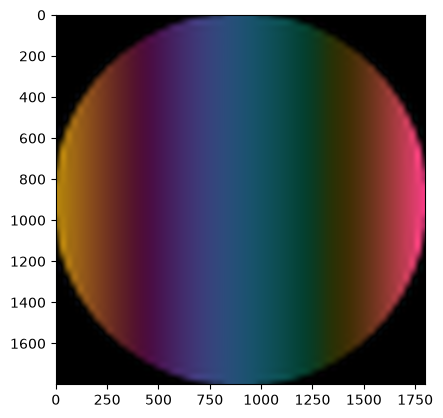

In [12]:
#Load input mode
input_mode = np.load('demos/mplc_input_single_mode.npy') #relative to workspace root

#zero pad the input mode so its array size scales by factor of oversizing (supports non-integer oversizing)
target_shape = [int(round(s * oversizing)) for s in input_mode.shape]
pad_widths = [((t - s) // 2, t - s - (t - s) // 2) for s, t in zip(input_mode.shape, target_shape)]
input_mode = np.pad(input_mode, pad_widths, mode='constant')

bin_size = 2  # Binning factor for the simulation

lc_pix_size = 10e-6  # Liquid crystal pixel size
simulation_pix_size = lc_pix_size / bin_size  # Simulation pixel size
wf_npixels = round(simulation_diameter / simulation_pix_size)  # Number of pixels in the simulation

print(wf_npixels)
print(simulation_pix_size)

#normalize input mode
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

#interpolate input mode to match wf_npixels using zoom
input_mode = zoom(input_mode, (wf_npixels / input_mode.shape[0], wf_npixels / input_mode.shape[1]), order=3)

plt.figure()
plt.imshow(apply_complex_map(input_mode))

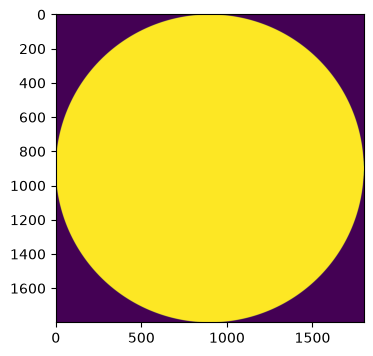

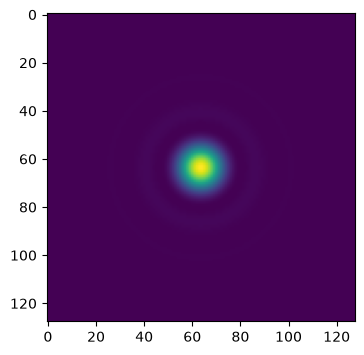

In [13]:
#Calculate output mode
focal_length = total_length # Effective focal length for spot generation

# Generate output modes by propagating a circular aperture
wf_npix = input_mode.shape[0]  # Number of pixels in the wavefront
circ_aper = dlu.circular_aperture(npixels=wf_npix, diameter = diameter, oversample=5, array_diameter=simulation_diameter)
circ_aper = circ_aper / np.sqrt(np.sum(np.abs(circ_aper)**2))  # Normalize the circular aperture
circ_aperture = dl.TransmissiveLayer(circ_aper, normalise=True)

# Define the propagator for generating the output modes (Pupil -> Focal)
psf_npix = 128  # Number of pixels in the PSF plane
psf_pixel_scale = diameter / wf_npix  # Pixel scale in the PSF plane
to_focal = dl.MFTPropagator(
    [
        ("ThinLens", dl.ABCDConjugatePlane(focal_length)),  # Pupil -> Focal
    ],
    dl.CoordSpec(n=psf_npix, d=psf_pixel_scale),
)

# Define the optical layers for generating the output modes
layers_mode_gen = [
    ("aperture", circ_aperture),
    ("to_focal", to_focal),
]

# Construct the optics object for generating the output modes
optics_mode_gen = dl.LayeredOpticalSystem(
    wf_npixels=wf_npix,
    diameter=diameter,
    layers=layers_mode_gen,
)

psf = optics_mode_gen.propagate(center_wavel, return_wf=True)
output_mode = psf.phasor[0]

plt.figure(figsize=(15, 4))
plt.imshow(circ_aper)

plt.figure(figsize=(15, 4))
plt.imshow(np.abs(output_mode)**2)

In [14]:
mplc_system = MPLCSystem(
    input_modes = np.array([input_mode]),
    target_modes = np.array([output_mode]),
    diameter = diameter,
    array_diameter = simulation_diameter,
    bin_size = bin_size,
    num_planes = num_planes,
    total_length = total_length,
    target_coordspec_n = psf_npix,
    target_coordspec_d = psf_pixel_scale,
    wavelengths = wavelengths)

In [15]:
# #make 3 randomized initial phase screens
# key = jax.random.PRNGKey(0)
# initial_phase_screens = jax.random.uniform(key, (3, mplc_system.wf_npixels, mplc_system.wf_npixels)) * 2 * np.pi

#initialize the phase screens with zeros
initial_phase_screens = np.zeros((num_planes, mplc_system.wf_npixels, mplc_system.wf_npixels))

In [ ]:
#Loss function
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM(params, mplc_system):
    mplc_system = mplc_system.with_params(params)
    return loss_WFM(stack_systems([mplc_system]))

#Loss function with misalignment
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM_misaligned(params, mplc_system, key, sigma_pix = 1.0):
    phase_screens = params['phase_screens']
    misaligned_phase_screens = apply_random_shifts(phase_screens, key, sigma_pix)
    params['phase_screens'] = misaligned_phase_screens
    mplc_system = mplc_system.with_params(params)
    return loss_WFM(stack_systems([mplc_system]))

In [27]:
params = {
    "phase_screens": initial_phase_screens,
    "total_length": np.array(total_length),
}

optimizers = {
    "phase_screens": optax.adam(learning_rate=1e-2),
    "total_length": optax.adam(learning_rate=1e-3),
}
optim, opt_state = zdx.map_optimisers(params, optimizers)

key = jax.random.PRNGKey(0)

#test the loss function
initial_loss, initial_grad = loss_fn_WFM_misaligned(params, mplc_system, key, sigma_pix = 1.0)
print("Initial loss:", initial_loss)
print("Initial gradient norm:", optax.global_norm(initial_grad))

Initial loss: 0.9998861
Initial gradient norm: 0.00022239452


In [28]:
# Run the optimisation loop
losses, params_out = [], []
num_iters = 1000
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        loss, grads = loss_fn_WFM_misaligned(params, mplc_system, key, sigma_pix = 1.0)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        # params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/1000 [00:00<?, ?it/s]

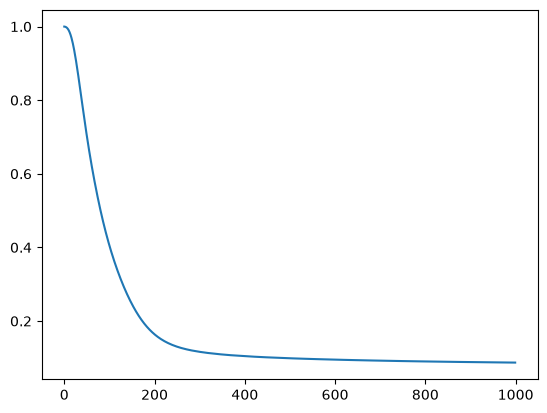

In [29]:
plt.figure()
plt.plot(losses)

1.0030179


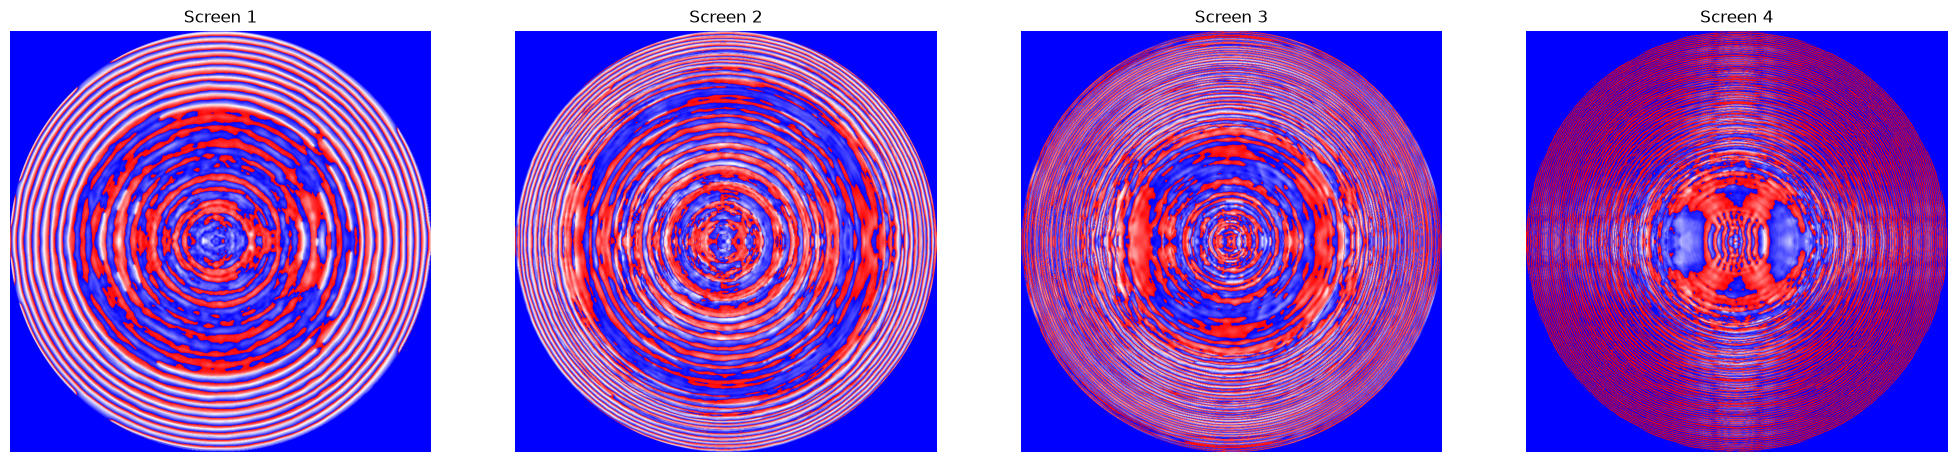

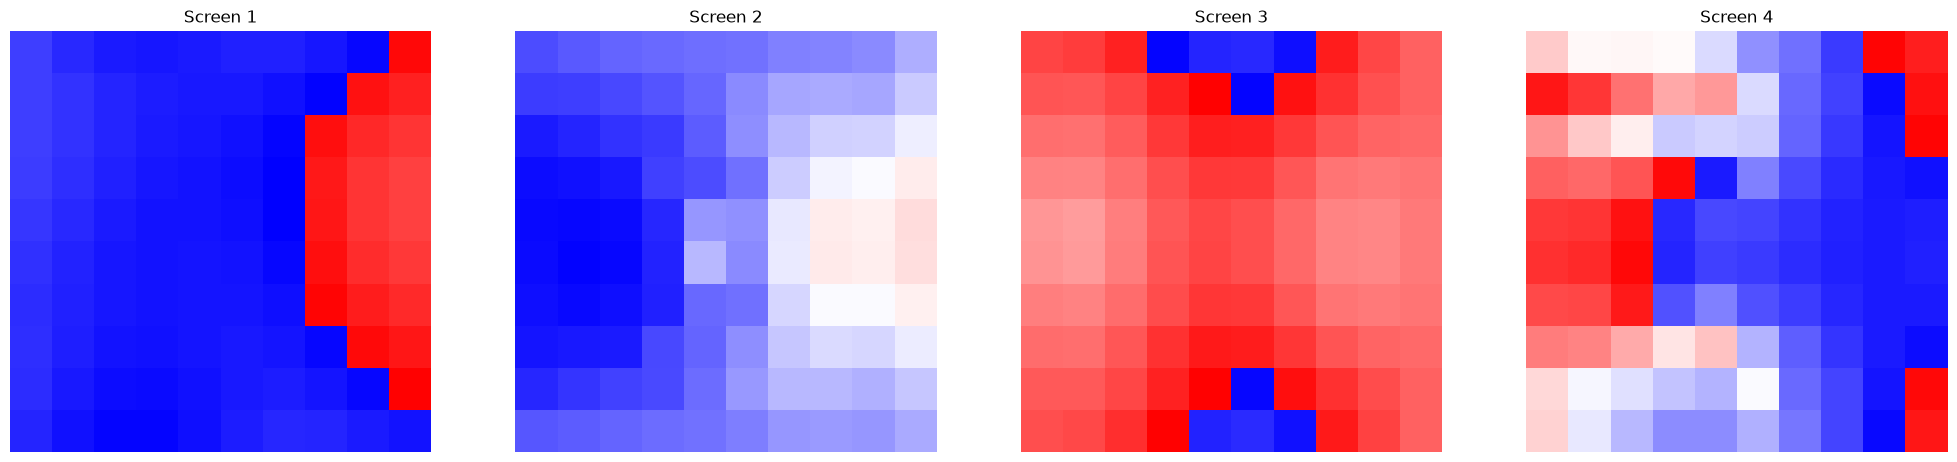

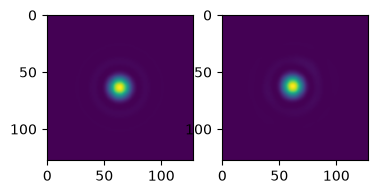

In [ ]:
#plot the final phase screens
mplc_system_final = mplc_system.with_params(params)
filtered_phase_screens_final = mplc_system_final.mplc.phase_screens

np.save('results/phase_screens_bandwidth02_jitter10um.npy', filtered_phase_screens_final)

#wrap phase screens between 0 and 2pi
wrapped_phase_screens_final = np.mod(filtered_phase_screens_final, 2 * np.pi)

plt.figure(figsize=(25, 8))
for i in range(num_planes):
    plt.subplot(1, num_planes, i+1)
    plt.imshow(wrapped_phase_screens_final[i], cmap='bwr', vmin=0, vmax=2*np.pi)
    plt.title(f'Screen {i+1}')
    plt.axis('off')

#plot the center 20 pixels of the final phase screens
crop = 10
center = filtered_phase_screens_final.shape[-1] // 2
plt.figure(figsize=(25, 8))
for i in range(num_planes):
    plt.subplot(1, num_planes, i+1)
    plt.imshow(wrapped_phase_screens_final[i][center-crop:center+crop, center-crop:center+crop], cmap='bwr', vmin=0, vmax=2*np.pi)
    plt.title(f'Screen {i+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
res_final = mplc_system_final()

print(params['total_length'])

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc_system.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)